## Project techniques - Where are we going

- You have seen your first permutation tests with FIOM and mosquitoes and beer

- In the rest of the course we will develop permutation techniques for the following cases [example real studies in ()]:

  - These cover a very large portion of the analyses in the scientific literature (or extensions of these -- e.g. multiple regression)

<img src = beer_water_exp_design.png width=400 align="right">

- Are there differences between means? (t-tests and ANOVA -- mosquitoes and beer)

<img src="gait_mat_vs_openpose.png" width=300 align="right">

### Are two variables related? (correlation and regression -- today)
  - covers both straight lines and curves </p>
  - current topic for me:  Are gait measures from smartphone video captured as accurately as from motion capture cameras?
  <br>

<img src="bilingualism_dementia.png" width = 500 align="right">  

### Are counts different in two (or more) categories (chi-square, log-linear analysis)
  - e.g. Is dementia less likely in bilingual people?
    - bilingual/mono-lingual
    - dementia/no dementia
    - <https://pmc.ncbi.nlm.nih.gov/articles/PMC11032525/ ></p>

- In class we ask if passenger class influenced who survived on the Titanic

<center>
<img src = "Titanic.png" width=400 align = "right"></p>
</center>


<img src="social_media_depression.png" width = 600 align="right">

- Is a binary outcome (yes/no) related to a continuous variable?
  - Is serious depression related to hours of social media exposure in young people?
    - serious depression/no depression - binary variable
    - hours of social media exposure - a continuous variable
    - Does the continuous variable predict the binary outcome?

### Relationships among variables: Straight lines (regression)
#### This will involve a very general technique that is also **_VERY_** useful to know 
<center>
    
### _Optimization_

</center>

<center>
    
###    _Examples of optimization problems_

</center>

## What is the shortest distance between a set of points? (travelling salesman problem)
<img src="travelling_salesman.png" width=500>

## What is the best shape for a car?

|   |   |
|----------------|----------------|
|<img src="aerodynamic_car1.jpg" width = 300 align="left"> | <img src="hq720.jpg" width = 300 align = "right"> |
|<img src="Rumpler_Tropfenwagen.jpg" width=300 align="left"> | <img src="martin_aerodynamic.jpg" width=300 align="right"> |
</p>


## Our case:  What is the best line through a set of points?

<img src="best_fit_line.png" width=300>

### To find the 'best' we are usually minimizing something
- Minimum distance travelled
- Minimum air resistance
- for lines: ?
- Maximum money saved - Ooooops!  This one wants the max!

#### USEFUL TRICK:  Note that a _maximization_ problem can be turned into a minimization problem by multiplying the answer by -1
e.g. money saved = £1000
- multiply by -1
- money_saved = -1000
- bigger amount saved = smaller number after $money\  \times$ -1

### Exercise:  Find a line with a good fit


#### Use the tool below to get some practice

<img src="LineTool.png" align=right width=500>

- What can you change?
  - Click on the red dot
  - Click on the line away from the red dot</p>

- What are you minimizing?

<https://www.geogebra.org/m/xC6zq7Zv>

- Make sure "Show regression line" is unchecked
- Click on "Randomize Data"
- Drag line to fit (notice what you can change)
- Click on "Show regression line"
- Check your fit
- Uncheck "Show regression line"
- Repeat
<br>

***What gets you the best line?***

### A first optimization problem: Here are some points to fit.  Let's plot them

In [1]:
# Just run this cell to import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
plt.style.use('fivethirtyeight')

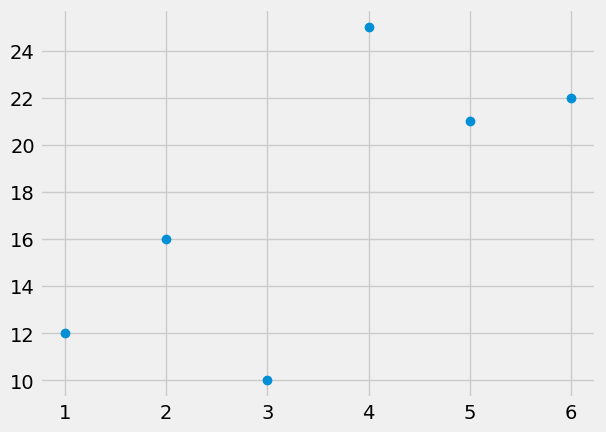

In [2]:
y_values = [12,16,10,25,21,22]
x_values = [1,2,3,4,5,6]

plt.plot(x_values,y_values,'o')

### Start simple: 
#### What _horizontal_ line is closest to all of these points?
#### A horizontal line is just a single value for Y, so that single value is all we can change

- Let's take a guess -- (start with a bad one)
- I'll start with 11

In [3]:
# A little function to plot errors -- just run this to load the function

def plot_guess_error(x_values,y_values,my_guess):
    my_guess_repeated = np.repeat(my_guess,len(x_values))
    plt.plot(x_values,y_values,'o')
    plt.plot(x_values, my_guess_repeated)
    for index in np.arange(len(x_values)):
        error_line_x=[x_values[index],x_values[index]]
        error_line_y=[my_guess,y_values[index]]
        plt.plot(error_line_x, error_line_y, \
                 linewidth=1, color="black")

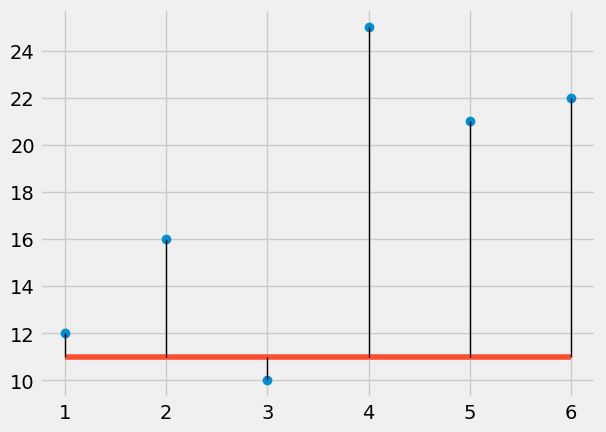

In [4]:
my_guess=11

plot_guess_error(x_values,y_values,my_guess)

#### What can we minimize to get the best fit?

### Vevox

In [1]:
# Write a function that produces the value you want to minimize

#### Try some guesses - find the best number

 my guess:  11  real data y value:  12  error:  -1  squared error:  1
total error so far:  1
 my guess:  11  real data y value:  16  error:  -5  squared error:  25
total error so far:  26
 my guess:  11  real data y value:  10  error:  1  squared error:  1
total error so far:  27
 my guess:  11  real data y value:  25  error:  -14  squared error:  196
total error so far:  223
 my guess:  11  real data y value:  21  error:  -10  squared error:  100
total error so far:  323
 my guess:  11  real data y value:  22  error:  -11  squared error:  121
total error so far:  444


444

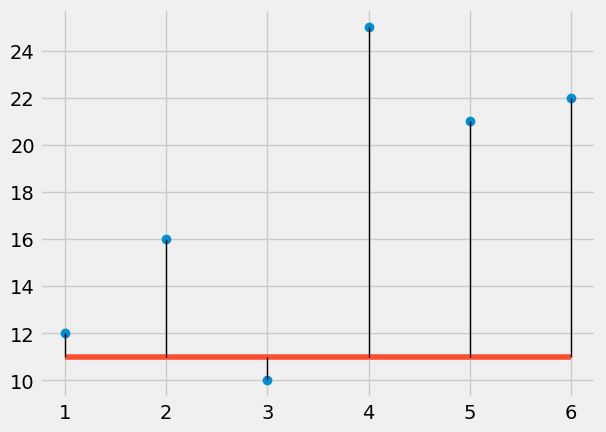

In [8]:
my_guess=11

plot_guess_error(x_values,y_values,my_guess)
sse_show(my_guess,y_values)

 my guess:  15  real data y value:  12  error:  3  squared error:  9
total error so far:  9
 my guess:  15  real data y value:  16  error:  -1  squared error:  1
total error so far:  10
 my guess:  15  real data y value:  10  error:  5  squared error:  25
total error so far:  35
 my guess:  15  real data y value:  25  error:  -10  squared error:  100
total error so far:  135
 my guess:  15  real data y value:  21  error:  -6  squared error:  36
total error so far:  171
 my guess:  15  real data y value:  22  error:  -7  squared error:  49
total error so far:  220


220

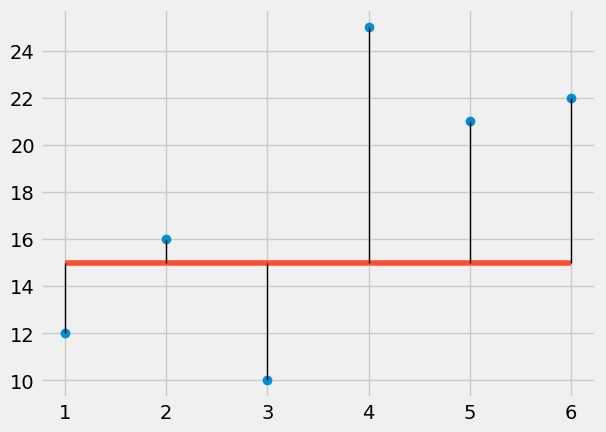

In [9]:
my_guess=15

plot_guess_error(x_values,y_values,my_guess)
sse_show(my_guess,y_values)

In [2]:
# function here

In [11]:
current_error = sse(15,y_values)
current_error

220

### Searching for the best value

- Try all values between 11 and 25

In [ ]:
# Try all values between 11 and 25
# See how the error (fit to the points) changes

guesses = [11,12,13,14,15,16,17,18,19,20,21,22,23,24,25]
total_error_values = np.zeros(len(guesses))
for i,current_guess in enumerate(guesses):
    total_error_values[i]=sse(current_guess,y_values)
    print("current guess for mean: ",current_guess," error: ",total_error_values[i])

## USEFUL PYTHON COMMAND
Notice the ```enumerate``` statement

```enumerate``` produces both a counter and a value

- ```i``` has the counter values
- ```current_guess``` has the **values** from the array ```guesses```

In [13]:
for i,current_guess in enumerate(guesses):
    print("i: ",i," current_guess: ",current_guess)

i:  0  current_guess:  11
i:  1  current_guess:  12
i:  2  current_guess:  13
i:  3  current_guess:  14
i:  4  current_guess:  15
i:  5  current_guess:  16
i:  6  current_guess:  17
i:  7  current_guess:  18
i:  8  current_guess:  19
i:  9  current_guess:  20
i:  10  current_guess:  21
i:  11  current_guess:  22
i:  12  current_guess:  23
i:  13  current_guess:  24
i:  14  current_guess:  25


#### Very useful!

#### Let's plot the SSE values for our guesses

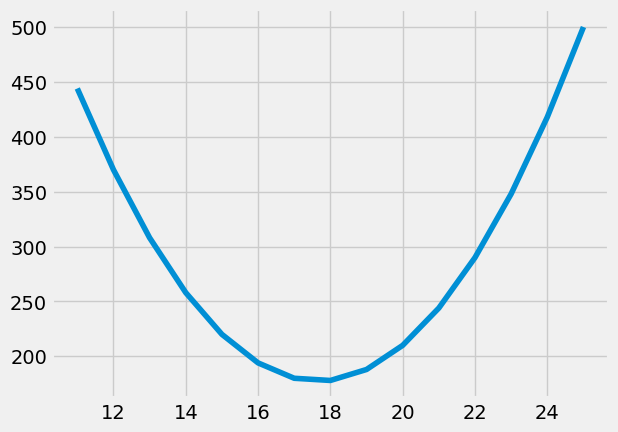

In [14]:
plt.plot(guesses,total_error_values)

#### What was the best integer guess?

[put your answer here]

#### Is that the best position?  (what about decimals between integers?)

[17.  17.1 17.2 17.3 17.4 17.5 17.6 17.7 17.8 17.9 18.  18.1 18.2 18.3
 18.4 18.5 18.6 18.7 18.8 18.9]
current guess for mean:  17.0  error:  180.0
current guess for mean:  17.1  error:  179.26
current guess for mean:  17.200000000000003  error:  178.63999999999996
current guess for mean:  17.300000000000004  error:  178.14
current guess for mean:  17.400000000000006  error:  177.75999999999996
current guess for mean:  17.500000000000007  error:  177.49999999999997
current guess for mean:  17.60000000000001  error:  177.36
current guess for mean:  17.70000000000001  error:  177.34
current guess for mean:  17.80000000000001  error:  177.44
current guess for mean:  17.900000000000013  error:  177.66000000000005
current guess for mean:  18.000000000000014  error:  178.00000000000006
current guess for mean:  18.100000000000016  error:  178.4600000000001
current guess for mean:  18.200000000000017  error:  179.04000000000013
current guess for mean:  18.30000000000002  error:  179.7400000000

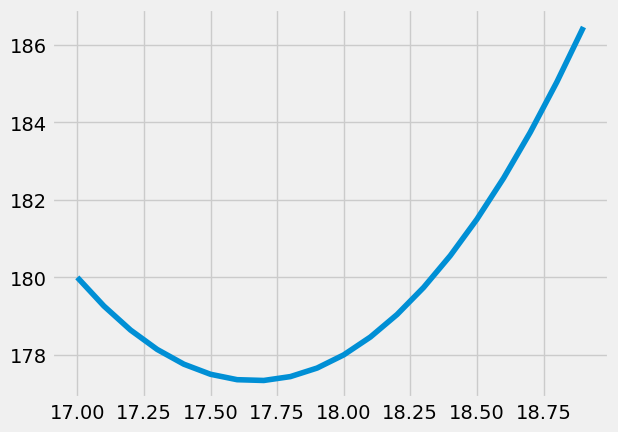

In [15]:
# Change this code to check some decimal values between the best integer numbers

# by hand guesses
# guesses = [11,12,13,14,15,16,17,18,19,20,21,22,23,24,25]

# np.arange version
guesses = np.arange(17, 19, .1)
print(guesses)
total_error_values = np.zeros(len(guesses))
for i,current_guess in enumerate(guesses):
    total_error_values[i]=sse(current_guess,y_values)
    print("current guess for mean: ",current_guess," error: ",total_error_values[i])

plt.plot(guesses, total_error_values)

### Python has a function to minimize the value from your error function (sse)

- If we minimize the error (calculated by our function ```sse```) we will have the best value for our collection of points
- call 'optimize.minimize' with
    - the function that calculates error
    - a starting guess

## There is an optimize library in the 'scipy' python module

#### The 'minimize' function adjusts the parameters you give it to find a minimum value
- `optimize.minimize` changes `guess` values
- until SSE is the smallest possible value


In [16]:
import scipy
from scipy import optimize

best_value=optimize.minimize(sse,[11], args=(y_values))
# first argument - sse - function that calculates the value to minimize
# [11] - the starting parameter (first guess) that will be adjusted
#        This array can have more than one value (e.g. for a line, the slope and intercept)
# args=(y_values) - The actual data values, `sse` needs these to calculate the error value
print("mean by optimization: ",best_value.x)

mean by optimization:  [17.6666669]


### Summary of the parts of the 'optimize' function call

```python
opt_mean=optimize.minimize(sse,[11],args=y_values)
```

| Part         | What is it?                                |
|:-------------|:-------------------------------------------|
| values to adjust    | The value(s) that python changes to find the minimum.  This can be an array of values if you are asking python to adjust more than one value.  |
| sse               | the **function** (NOT a variable) **we have written** that calculates the ONE value we want to minimize |
| an **array**      | the starting values for the values that 'optimize' can change  - here we have just one value - our first guess - 11 |
| args=y_values     | these are other arguments that get passed to sse, but not changed by optimize |


#### Notice we get the same value if we take the mean:

In [17]:
np.mean(y_values)

np.float64(17.666666666666668)

- You've learned something about the mean as well
- The mean is the y value that is closest to all of the y values in a dataset

#### Obviously this is a 'toy' problem because the mean is easy to calculate, _BUT (but,but)_

- The code using ```optimize.minimize`` doesn't change much for other (much more complex) problems
  - (although sometimes the function (SSE here) can be complicated)
- The alternative (by formula) can get _very_ complicated
- Sometimes (even often) there is NO formula (without the 'optimize.minimize' solution you are stuck)
<br>  

- Learn to use ```optimize.minimize``` and you can apply this to many cases

### <span style="color:green"> Speaking of lines...Now make 'optimize' work for a line </span>

### Reminder - formula for a line


The equation for a line is:
    
$$y = mx + b$$

Where:  
y = a value from you data that you want to predict  
x = a value from your data that you think predicts y (e.g. if ```y=weight``` ```x``` might be ```height```)  
m = the slope of the line relating x and y  (how many kilos does every cm of height add?)
b = the y intercept of the line -- where the line touches the y axis  

#### So we have _two_ values to change this time
- **The slope and the intercept**

Compare to the case for the mean -- we just had to optimize one value

### Exercise -- Write the code to fit the best line possible 
- any line, not just a horizontal line

#### Here are some points to use:

In [ ]:
line_to_fit = pd.read_csv("line_to_fit.csv")
plt.scatter(line_to_fit["x"],line_to_fit["y"])

#### Steps

- Write your error function - SSE for points on a line
  - Loop through all points and calculate an error value for each
    - Get the x value from the point
    - Get the y value from the same point
    - Use the slope and intercept for the line (pass these to the function)
      - Calculate the line's y-value using the point's x-value
      - Remember $line\_y\_value\ =\ intercept\ +\ (slope\ \times\ point\_x\_value)$
    - Calculate the squared distance between the line's y-value and the point's y-value
    - Store this value
  - Sum up the error values 


In [ ]:
# Start of your SSE function
def sse(values_to_change,x_values,y_values):
# values_to_change are the slope and intercept values in an array, e.g.
#        [slope,intercept]
# YOU have to set the order of the values passed to sse.  
# Do you want [slope, intercept] or [intercept, slope]?
# Remember what you choose because the answer at the end will have
# values in the same order
#
# x_values are the x_values for the points
# y_values are the y_values for the points
#
# An example call to sse might be 
#       slope = 2
#       intercept = 3
#       sse_value = sse([slope,intercept], x_points, y_points)

# finish the function here
    return(total_error)

#### Once you have the SSE function written, use it with optimize minimize to get the best fit line

In [ ]:
# e.g.
x_values = line_to_fit["x"]
y_values = line_to_fit["y"]
result = optimize.minimize(sse,[1,5], args=(x_values,y_values))

#### The optimized values are in "x"

- 2.029 is the optimized value for the slope
- 7.843 is the optimized value for the intercept

Do these make sense?
- Does the line cross the y-axis at about 7.843?
  - Hard to see here because of the scale, but looks close to zero which is about right when the scale is big
- Does the line go up 2 y values for every x value (e.g. is [100,200] on the line)?
  - Yes - looks right